# Customer Churn Prediction (Bank Customers)

**Goal:** predict whether a bank customer will leave (`Exited = 1`) using the `Churn_Modelling.csv` dataset.

**Workflow**
1. Imports
2. Load data and basic checks
3. Exploratory Data Analysis (EDA)
4. Preprocessing (label encoding, train / validation / test split, SMOTE)
5. Model training: Decision Tree, Random Forest, XGBoost (with early stopping)
6. Cross-validation, evaluation and model comparison
7. Feature importance and saving the best model


## 1. Import dependencies

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Import label encoder for converting categorical text columns to numbers
from sklearn.preprocessing import LabelEncoder

# Import SMOTE (oversampling) and imblearn's Pipeline (so SMOTE runs inside each CV fold only)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Import splitting and cross-validation helpers
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, f1_score,
                             classification_report, roc_auc_score, roc_curve)
import joblib
import warnings
warnings.filterwarnings("ignore")

# Set a clean default plot style and a global random seed for reproducibility
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load the data

In [2]:
# Load the dataset (keep Churn_Modelling.csv in the same folder as this notebook)
df = pd.read_csv(r"Churn_Modelling.csv")

# Check the number of rows and columns
print("Shape:", df.shape)

# Preview the first five rows
df.head()

Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 3. Exploratory Data Analysis (EDA)

In [3]:
# Look at column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [4]:
# Summary statistics for the numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


In [5]:
# Check for missing values and duplicate rows
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Duplicate rows: 0


In [6]:
# Drop identifier columns: RowNumber, CustomerId and Surname carry no predictive signal
# (they are unique labels, not customer behaviour) and could cause overfitting
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print("Remaining columns:", list(df.columns))

Remaining columns: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


        count  percent
Exited                
0        7963    79.63
1        2037    20.37


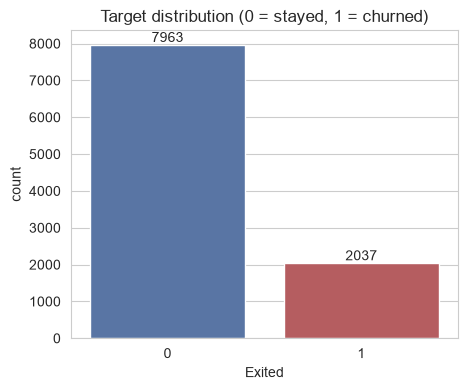

In [7]:
# Check the target balance: how many customers stayed (0) vs churned (1)
counts = df["Exited"].value_counts()
percent = df["Exited"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))

# Plot the class distribution
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Exited", data=df, palette=["#4C72B0", "#C44E52"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Target distribution (0 = stayed, 1 = churned)")
plt.show()

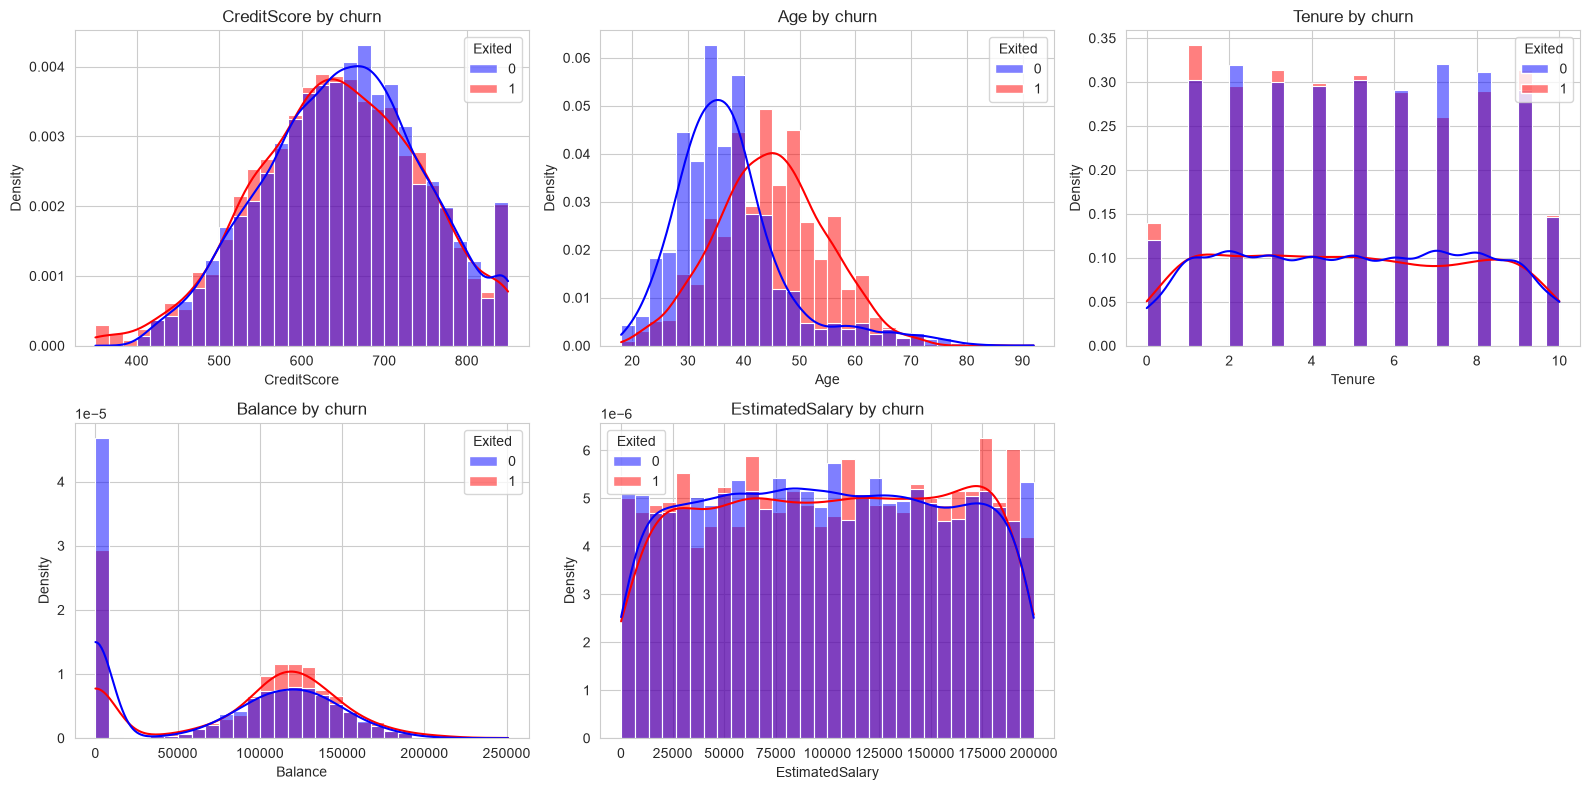

In [9]:
# Plot distributions of the numeric features, split by churn status
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue="Exited", kde=True, bins=30, ax=ax,
                 palette=["blue", "red"], stat="density", common_norm=False)
    ax.set_title(f"{col} by churn")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

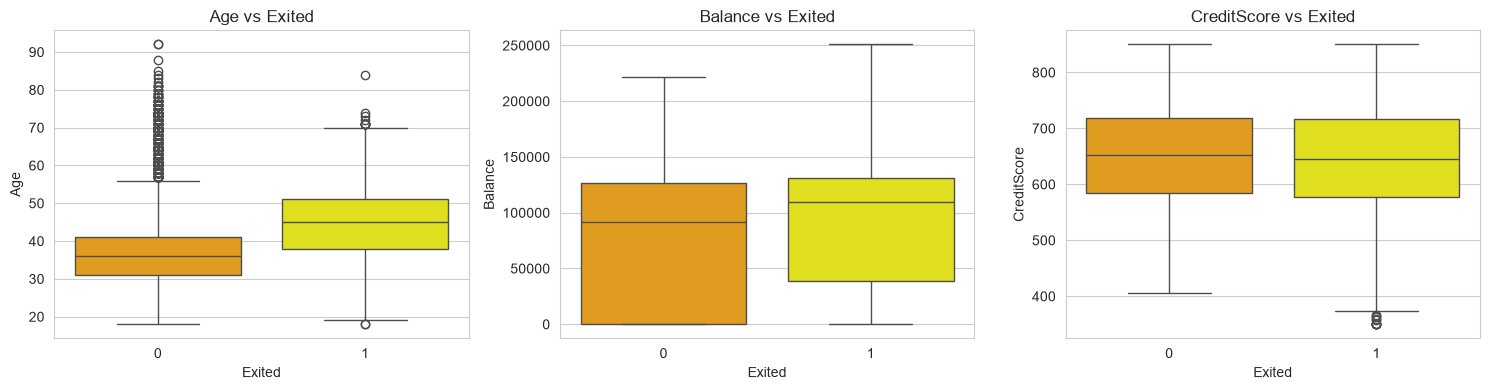

Customers with zero balance: 36.2%


In [11]:
# Compare Age and Balance between churned and retained customers using boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "Balance", "CreditScore"]):
    sns.boxplot(x="Exited", y=col, data=df, ax=ax, palette=["orange", "yellow"])
    ax.set_title(f"{col} vs Exited")
plt.tight_layout()
plt.show()

# Check how many customers have a zero balance
print(f"Customers with zero balance: {(df['Balance'] == 0).mean() * 100:.1f}%")

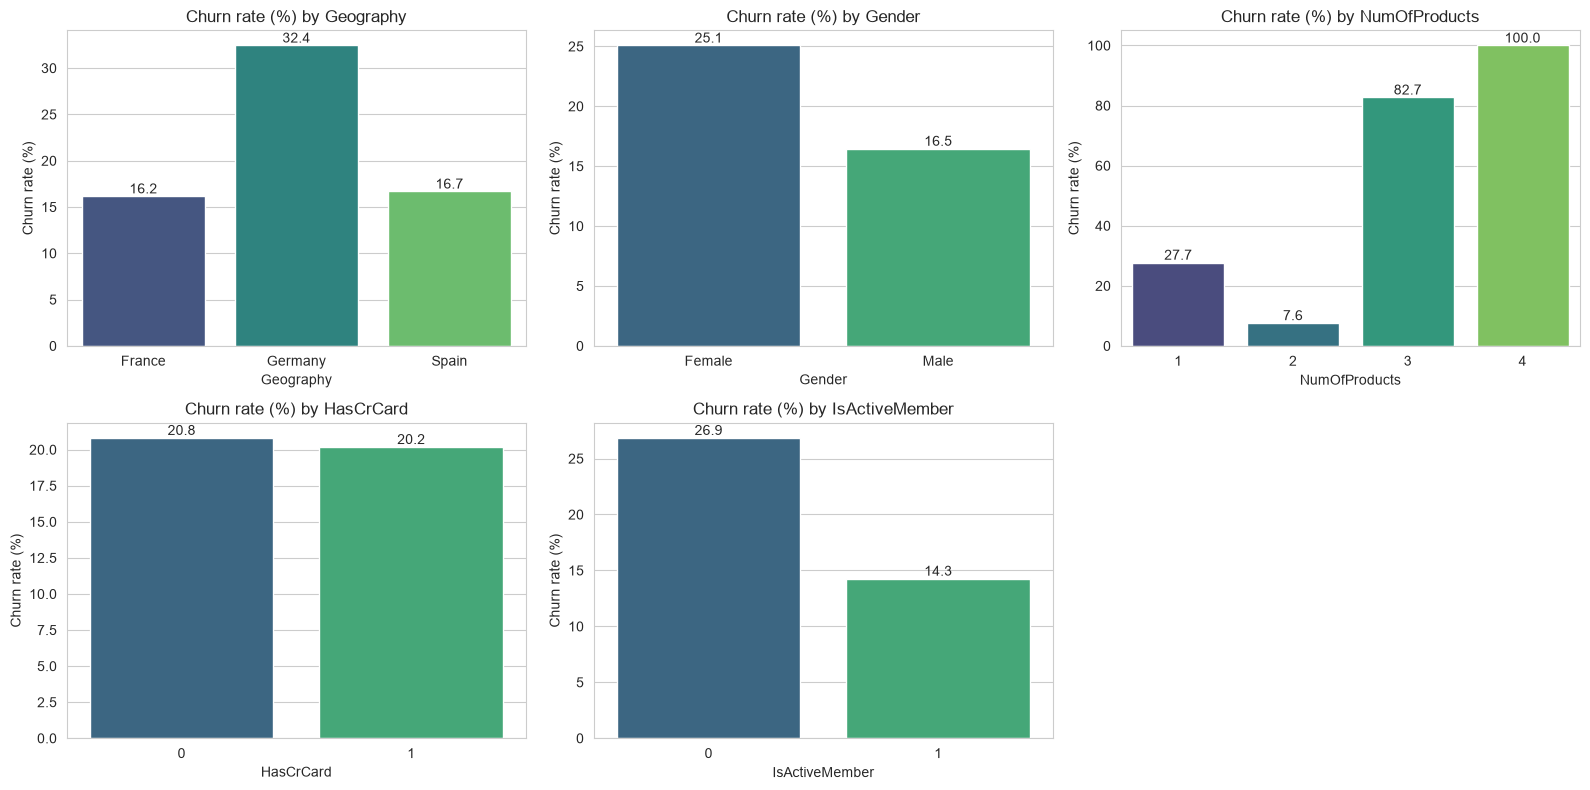

In [12]:
# Plot the churn rate for each categorical / low-cardinality feature
cat_cols = ["Geography", "Gender", "NumOfProducts", "HasCrCard", "IsActiveMember"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)["Exited"].mean().mul(100)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, palette="viridis")
    ax.set_title(f"Churn rate (%) by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel(col)
    for i, v in enumerate(rate.values):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

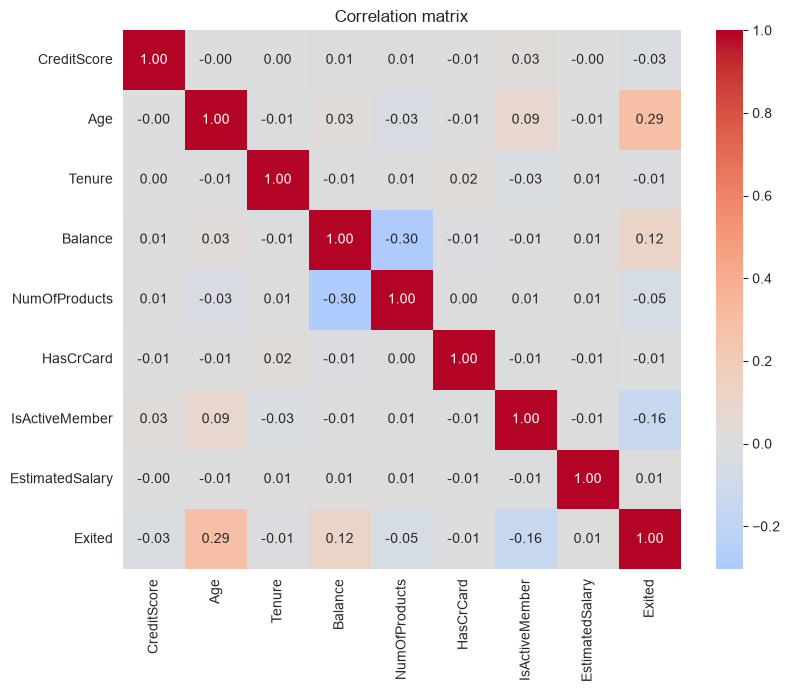

In [13]:
# Plot a correlation heatmap of the numeric columns to spot relationships with churn
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

### EDA takeaways
- **Class imbalance:** about 20% of customers churned, so accuracy alone is misleading. We will use F1 and ROC-AUC, and SMOTE on the training data.
- **No missing values or duplicates** in this dataset.
- **Age** is the strongest numeric signal: churned customers are noticeably older (mean about 45 vs 37).
- **Geography:** Germany has roughly double the churn rate of France and Spain.
- **Gender:** female customers churn more than male customers.
- **Activity:** inactive members churn at nearly twice the rate of active members.
- **NumOfProducts:** customers with 3 or 4 products churn at very high rates, while those with 2 products churn the least.
- **HasCrCard** and **EstimatedSalary** show little relationship with churn.

## 4. Preprocessing

In [14]:
# Label-encode the two text columns (Geography, Gender) and keep each encoder for later use
# Note: tree-based models do not need feature scaling, so we skip scaling here
label_encoders = {}
for col in ["Geography", "Gender"]:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
    print(col, "->", {cls: int(code) for cls, code in zip(le.classes_, le.transform(le.classes_))})

Geography -> {'France': 0, 'Germany': 1, 'Spain': 2}
Gender -> {'Female': 0, 'Male': 1}


In [15]:
# Separate the features (X) from the target (y)
X = df.drop(columns=["Exited"])
y = df["Exited"]
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (10000, 10) | y shape: (10000,)


In [16]:
# Hold out a 20% test set (stratified so the churn ratio is preserved).
# The test set is untouched until final evaluation to avoid data leakage.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

# Split a validation set out of the training data; XGBoost uses it for early stopping
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20, stratify=y_train_full, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

Train: (6400, 10) | Validation: (1600, 10) | Test: (2000, 10)


In [17]:
# Apply SMOTE to the TRAINING portion only (never to validation/test data) to balance the classes
smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# Compare class counts before and after SMOTE
print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_res.value_counts().to_dict())

Before SMOTE: {0: 5096, 1: 1304}
After SMOTE:  {1: 5096, 0: 5096}


## 5. Define the models

In [18]:
# Define the three models. Hyperparameters are moderately regularised to limit overfitting.
dt_model = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE)

rf_model = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5,
                                  n_jobs=-1, random_state=RANDOM_STATE)

# XGBoost: allow up to 1000 trees but stop when validation AUC has not improved for 50 rounds.
# Early stopping keeps the best iteration automatically when predicting.
xgb_model = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=4,
                          subsample=0.8, colsample_bytree=0.8,
                          eval_metric="auc", early_stopping_rounds=50,
                          random_state=RANDOM_STATE, n_jobs=-1)

# A copy of XGBoost without early stopping, used only for cross-validation
# (early stopping needs a validation set, which cross_val_score does not provide)
xgb_cv_model = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             subsample=0.8, colsample_bytree=0.8, eval_metric="auc",
                             random_state=RANDOM_STATE, n_jobs=-1)

## 6. Cross-validation
SMOTE is placed **inside** an `imblearn` pipeline so that in each fold it only resamples that fold's training part. Applying SMOTE before cross-validation would leak synthetic copies of validation samples into training and inflate the scores.

In [19]:
# Run 5-fold stratified cross-validation on the training data for each model (SMOTE applied inside each fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_models = {"Decision Tree": dt_model, "Random Forest": rf_model, "XGBoost": xgb_cv_model}

cv_results = []
for name, model in cv_models.items():
    pipe = ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)), ("model", model)])
    auc_scores = cross_val_score(pipe, X_train_full, y_train_full, cv=cv, scoring="roc_auc")
    f1_scores = cross_val_score(pipe, X_train_full, y_train_full, cv=cv, scoring="f1")
    cv_results.append({"Model": name,
                       "CV ROC-AUC (mean)": auc_scores.mean(), "CV ROC-AUC (std)": auc_scores.std(),
                       "CV F1 (mean)": f1_scores.mean(), "CV F1 (std)": f1_scores.std()})

cv_df = pd.DataFrame(cv_results).set_index("Model").round(4)
cv_df

,CV ROC-AUC (mean),CV ROC-AUC (std),CV F1 (mean),CV F1 (std)
Model,,,,
Decision Tree,0.8082,0.0162,0.5373,0.0186
Random Forest,0.8342,0.0171,0.5756,0.0222
XGBoost,0.8428,0.0157,0.5943,0.0260


## 7. Train the final models

In [20]:
# Train the Decision Tree and Random Forest on the SMOTE-balanced training data
dt_model.fit(X_train_res, y_train_res)
rf_model.fit(X_train_res, y_train_res)
print("Decision Tree and Random Forest trained.")

Decision Tree and Random Forest trained.


In [21]:
# Train XGBoost with early stopping: the untouched validation set monitors AUC after every tree
xgb_model.fit(X_train_res, y_train_res,
              eval_set=[(X_val, y_val)],
              verbose=False)

# Report how many trees were actually kept
best_iter = getattr(xgb_model, "best_iteration", None)
print("Best iteration:", best_iter, "| Best validation AUC:", getattr(xgb_model, "best_score", None))

Best iteration: 181 | Best validation AUC: 0.8291502537777735


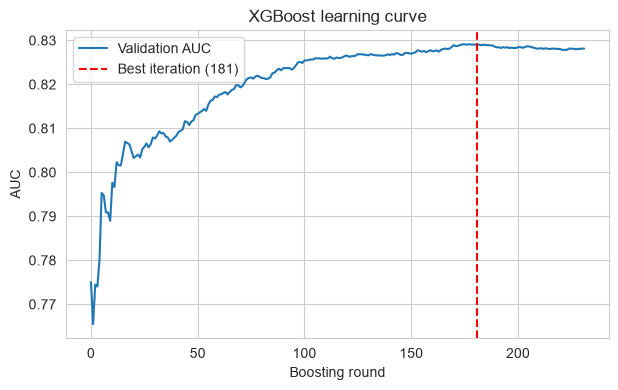

In [23]:
# Plot the XGBoost validation AUC per boosting round to see where early stopping kicked in
history = xgb_model.evals_result()
metric_name = list(history["validation_0"].keys())[0]
plt.figure(figsize=(7, 4))
plt.plot(history["validation_0"][metric_name], label="Validation AUC")
if best_iter is not None:
    plt.axvline(best_iter, color="red", linestyle="--", label=f"Best iteration ({best_iter})")
plt.xlabel("Boosting round")
plt.ylabel("AUC")
plt.title("XGBoost learning curve")
plt.legend()
plt.show()

## 8. Evaluation on the held-out test set

In [24]:
# Helper that evaluates one model: prints a classification report, draws a confusion matrix,
# and returns the key metrics (accuracy, F1, ROC-AUC) plus predicted probabilities
def evaluate_model(name, model, X_eval, y_eval, ax=None):
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]

    acc = accuracy_score(y_eval, y_pred)
    f1 = f1_score(y_eval, y_pred)
    auc = roc_auc_score(y_eval, y_proba)

    print(f"===== {name} =====")
    print(f"Accuracy: {acc:.4f} | F1: {f1:.4f} | ROC-AUC: {auc:.4f}")
    print(classification_report(y_eval, y_pred, target_names=["Stayed", "Churned"]))

    if ax is not None:
        sns.heatmap(confusion_matrix(y_eval, y_pred), annot=True, fmt="d", cmap="Blues",
                    xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"], ax=ax)
        ax.set_title(name)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    return {"Model": name, "Accuracy": acc, "F1 (churn)": f1, "ROC-AUC": auc}, y_proba

===== Decision Tree =====
Accuracy: 0.7900 | F1: 0.5503 | ROC-AUC: 0.8282
              precision    recall  f1-score   support

      Stayed       0.90      0.83      0.86      1593
     Churned       0.49      0.63      0.55       407

    accuracy                           0.79      2000
   macro avg       0.69      0.73      0.71      2000
weighted avg       0.81      0.79      0.80      2000

===== Random Forest =====
Accuracy: 0.8090 | F1: 0.5784 | ROC-AUC: 0.8377
              precision    recall  f1-score   support

      Stayed       0.90      0.85      0.88      1593
     Churned       0.53      0.64      0.58       407

    accuracy                           0.81      2000
   macro avg       0.71      0.75      0.73      2000
weighted avg       0.83      0.81      0.82      2000

===== XGBoost =====
Accuracy: 0.8080 | F1: 0.5871 | ROC-AUC: 0.8489
              precision    recall  f1-score   support

      Stayed       0.91      0.84      0.87      1593
     Churned       0.

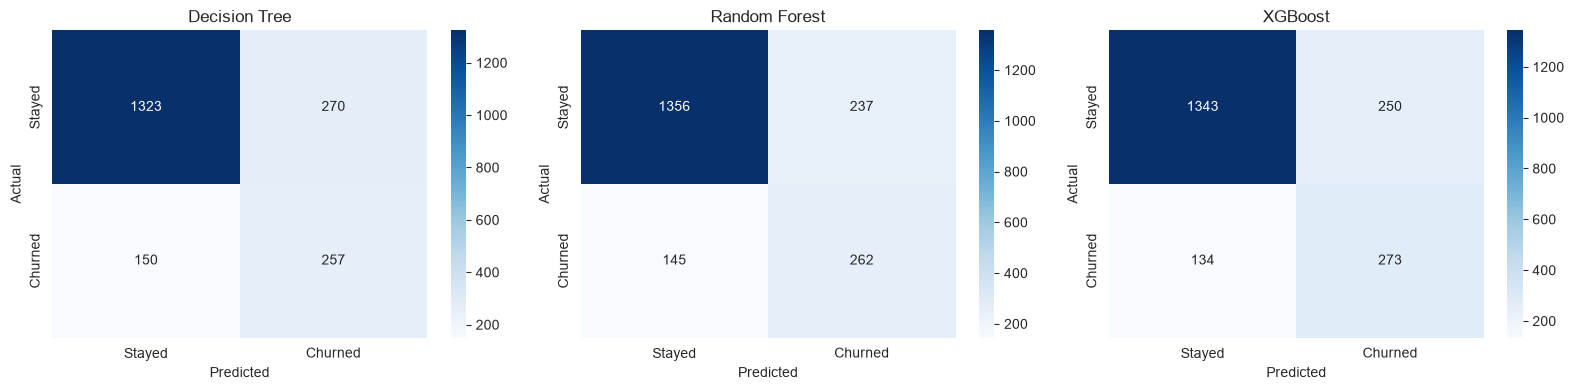

In [25]:
# Evaluate all three models on the test set and draw their confusion matrices side by side
trained_models = {"Decision Tree": dt_model, "Random Forest": rf_model, "XGBoost": xgb_model}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
results, probas = [], {}
for ax, (name, model) in zip(axes, trained_models.items()):
    metrics, proba = evaluate_model(name, model, X_test, y_test, ax=ax)
    results.append(metrics)
    probas[name] = proba
plt.tight_layout()
plt.show()

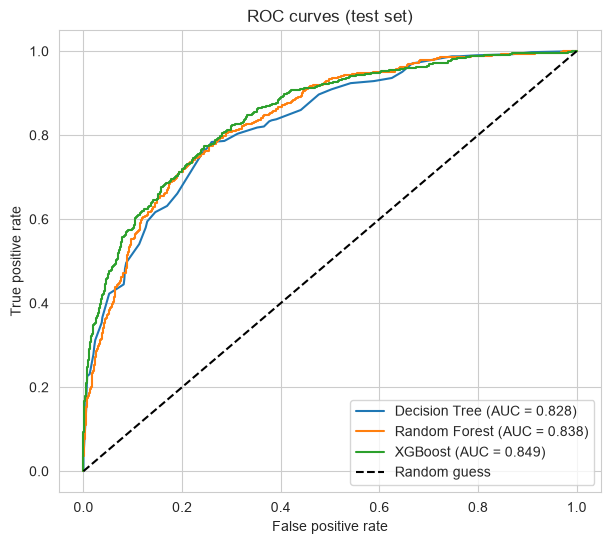

In [26]:
# Plot ROC curves for all models on one chart
plt.figure(figsize=(7, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves (test set)")
plt.legend()
plt.show()

In [27]:
# Build a comparison table of the test results, sorted by ROC-AUC
results_df = pd.DataFrame(results).set_index("Model").sort_values("ROC-AUC", ascending=False).round(4)
results_df

,Accuracy,F1 (churn),ROC-AUC
Model,,,
XGBoost,0.808,0.5871,0.8489
Random Forest,0.809,0.5784,0.8377
Decision Tree,0.790,0.5503,0.8282


## 9. Feature importance

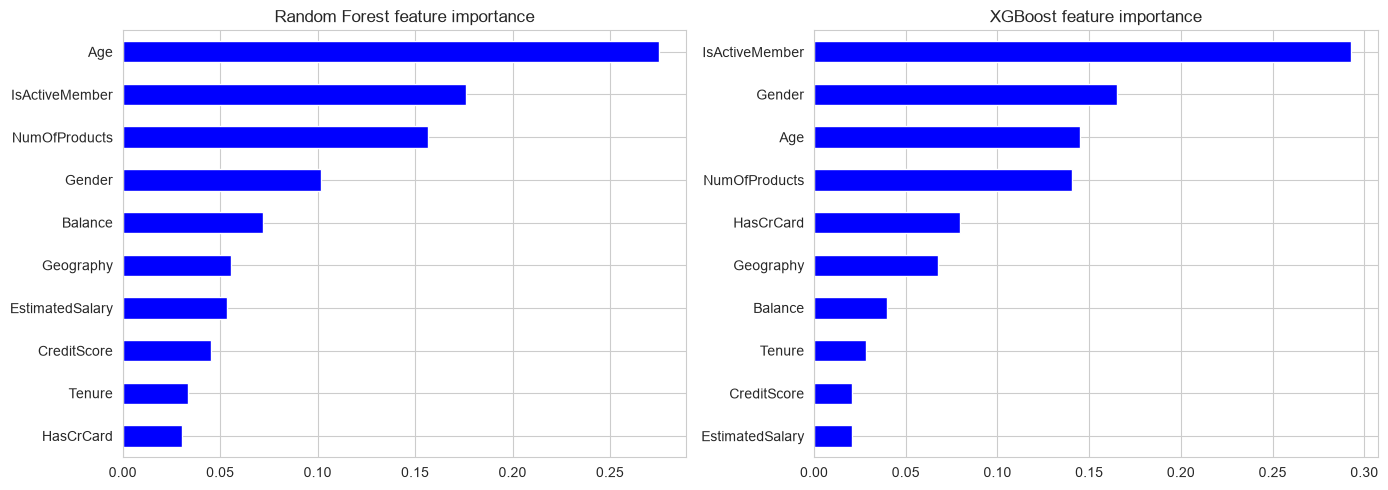

In [28]:
# Compare feature importances from Random Forest and XGBoost to see what drives churn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, model) in zip(axes, [("Random Forest", rf_model), ("XGBoost", xgb_model)]):
    imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
    imp.plot(kind="barh", ax=ax, color= "blue")
    ax.set_title(f"{name} feature importance")
plt.tight_layout()
plt.show()

## 10. Save the best model

In [29]:
# Pick the best model by test ROC-AUC and save it together with the label encoders
# so new data can be encoded and scored the same way later
best_name = results_df.index[0]
best_model = trained_models[best_name]

joblib.dump({"model": best_model, "label_encoders": label_encoders, "features": list(X.columns)},
            "best_churn_model.pkl")
print(f"Saved '{best_name}' to best_churn_model.pkl")

Saved 'XGBoost' to best_churn_model.pkl


In [30]:
# Example: load the saved model and rank the test customers by churn probability (top 10 at risk)
artifact = joblib.load("best_churn_model.pkl")
risk = X_test.copy()
risk["churn_probability"] = artifact["model"].predict_proba(X_test[artifact["features"]])[:, 1]
risk["actual_exited"] = y_test.values
risk.sort_values("churn_probability", ascending=False).head(10)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,churn_probability,actual_exited
6831,469,1,0,52,8,139493.25,3,0,0,150093.32,0.993928,1
6255,547,1,1,55,4,111362.76,3,1,0,16922.28,0.993634,1
5950,834,1,0,57,8,112281.60,3,1,0,140225.14,0.993511,1
3549,675,0,0,61,5,62055.17,3,1,0,166305.16,0.992857,1
70,738,1,1,58,2,133745.44,4,1,0,28373.86,0.992360,1
8396,607,0,0,48,4,112070.86,3,1,0,173568.30,0.991572,1
871,629,1,0,45,7,129818.39,3,1,0,9217.55,0.985992,1
1798,714,0,0,51,4,88308.87,3,0,0,5862.53,0.985594,1
2312,545,0,0,55,5,0.00,1,0,0,10034.77,0.983560,1
7435,610,2,0,50,5,130554.51,3,1,0,184758.17,0.983287,1


## Notes and next steps
- **Metrics:** with about 20% churners, look at F1 and ROC-AUC for the churn class, not accuracy only. The model is chosen using the test set here for simplicity; for a stricter setup, choose with cross-validation and use the test set once at the end.
- **Threshold tuning:** the default 0.5 cutoff is not necessarily the best for the business. If missing a churner costs more than a retention offer, lower the threshold to raise recall.
- **Ideas to improve:** hyperparameter search (`RandomizedSearchCV`), one-hot encoding for `Geography`, engineered features (e.g. balance-to-salary ratio, age groups), and SHAP for explanations.